In [4]:
# Customer Segmentation

In [1]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import plotly.express as px
import plotly.graph_objects as go
import matplotlib.pyplot as plt

data = pd.read_csv(
    'C:/Users/Mega-Pc/Freelance/data/ecommerce/data_cleaned+scaled.csv',encoding='ISO-8859-1')

In [12]:
print(list(data.columns))


['Quantity', 'UnitPrice', 'CustomerID', 'TotalPrice', 'DescriptionLength', 'NumWordsInDescription', 'IsReturn', 'InvoiceHour', 'InvoiceDayOfWeek', 'InvoiceMonth', 'InvoiceQuarter', 'IsWeekend', 'IsHolidaySeason', 'NumUniqueItems', 'TotalQuantity', 'AvgPricePerItem', 'NumTransactions', 'TotalSpent', 'AvgTransactionValue', 'MaxTransactionValue', 'AvgItemsPerTransaction', 'ReturnRate', 'NumUniqueItemsBought', 'RecencyDays', 'TenureDays', 'TenureMonths', 'FrequencyPerMonth', 'MonetaryPerMonth', 'AvgDaysBetweenInvoices', 'TotalQuantitySold', 'TotalRevenueGenerated', 'AvgUnitPriceSold', 'NumUniqueCustomers', 'PricePerUnitDeviation', 'CustomerProductAffinity', 'InvoiceDiversity', 'CountryAvgSpend', 'CountryAvgSpendDeviation', 'Recency_x_Frequency', 'Frequency_x_Monetary', 'ProductClusterSemantic', 'SentimentScore', 'IsDeluxe', 'ClusterCount_0', 'ClusterCount_1', 'ClusterCount_2', 'ClusterCount_3', 'ClusterCount_4', 'DeluxeRatio', 'AvgSentimentScore', 'SentimentEncoded', 'Country_Austria', 'Co

In [3]:
customer_df = data.groupby('CustomerID').agg({
    'TotalSpent': 'sum',
    'NumTransactions': 'sum',
    'AvgTransactionValue': 'mean',
    'ReturnRate': 'mean',
    'RecencyDays': 'mean',
    'FrequencyPerMonth': 'mean',
    'MonetaryPerMonth': 'mean',
    'AvgDaysBetweenInvoices': 'mean',
    'CountryAvgSpendDeviation': 'mean',
    'SentimentScore': 'mean',
    'IsDeluxe': 'mean'
}).reset_index()


In [4]:
customer_df

,CustomerID,TotalSpent,NumTransactions,AvgTransactionValue,ReturnRate,RecencyDays,FrequencyPerMonth,MonetaryPerMonth,AvgDaysBetweenInvoices,CountryAvgSpendDeviation,SentimentScore,IsDeluxe
0,0.000000,0.008780,0.008097,0.332581,0.500000,0.871314,0.004556,0.005046,0.000000,0.365885,0.722222,0.000000
1,0.000168,7.162460,4.421053,0.380529,0.000000,0.002681,0.001714,0.004758,0.285714,0.386876,0.448499,0.010989
2,0.000337,0.288458,0.376518,0.369183,0.000000,0.198391,0.001089,0.003076,0.386301,0.374307,0.436081,0.000000
3,0.000505,1.194043,0.000000,0.370292,0.000000,0.048257,0.004556,0.005046,0.000000,0.388099,0.475420,0.027397
4,0.000673,0.118846,0.000000,0.368406,0.000000,0.828418,0.004556,0.005046,0.000000,0.364388,0.450980,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
4367,0.998822,0.058378,0.000000,0.367350,0.000000,0.742627,0.004556,0.005046,0.000000,0.398919,0.428704,0.000000
4368,0.998990,0.033732,0.000000,0.337934,0.000000,0.482574,0.004556,0.005046,0.000000,0.370971,0.424603,0.285714
4369,0.999158,0.072951,0.105263,0.347011,0.076923,0.018767,0.002495,0.002938,0.215525,0.379595,0.440781,0.000000
4370,0.999327,16.335173,43.785425,0.317331,0.000000,0.008043,0.005325,0.003879,0.114041,0.351395,0.438885,0.011096


In [5]:
features = ['TotalSpent', 'AvgTransactionValue', 'MonetaryPerMonth', 
             'RecencyDays', 'FrequencyPerMonth', 'AvgDaysBetweenInvoices',
             'ReturnRate', 'SentimentScore', 'IsDeluxe']

X = customer_df[features]

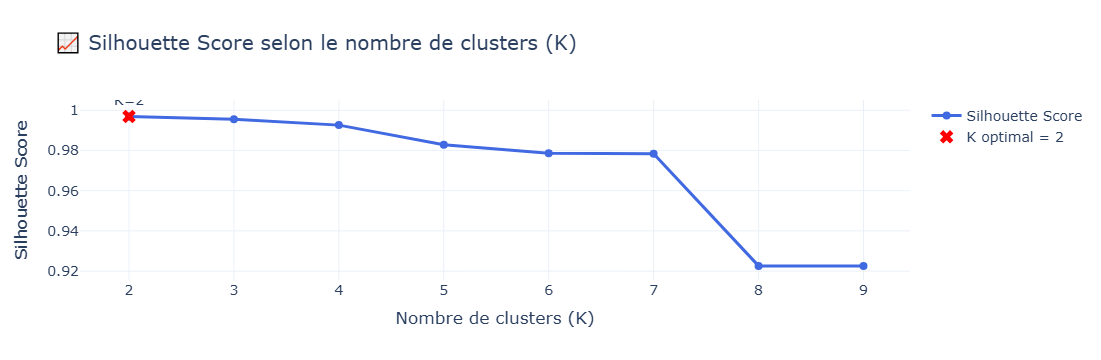

K optimal = 2 avec un score de silhouette de 0.997


In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import plotly.graph_objects as go


scores = []
K_range = range(2, 10)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)  
    score = silhouette_score(X, kmeans.labels_)
    scores.append(score)


optimal_k = K_range[np.argmax(scores)]
optimal_score = max(scores)

fig = go.Figure()


fig.add_trace(go.Scatter(
    x=list(K_range),
    y=scores,
    mode='lines+markers',
    name='Silhouette Score',
    line=dict(color='royalblue', width=3),
    marker=dict(size=8)
))


fig.add_trace(go.Scatter(
    x=[optimal_k],
    y=[optimal_score],
    mode='markers+text',
    name=f'K optimal = {optimal_k}',
    text=[f'K={optimal_k}'],
    textposition="top center",
    marker=dict(color='red', size=12, symbol='x')
))


fig.update_layout(
    title="📈 Silhouette Score selon le nombre de clusters (K)",
    xaxis_title="Nombre de clusters (K)",
    yaxis_title="Silhouette Score",
    template="plotly_white",
    font=dict(size=14),
    showlegend=True
)

fig.show()

print(f"K optimal = {optimal_k} avec un score de silhouette de {optimal_score:.3f}")


In [10]:
optimal_k = 2  
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
customer_df['Cluster'] = kmeans.fit_predict(X)


In [11]:
cluster_profile = customer_df.groupby('Cluster')[features].mean().round(2)
print(cluster_profile)


         TotalSpent  AvgTransactionValue  MonetaryPerMonth  RecencyDays  \
Cluster                                                                   
0              3.96                 0.37              0.01         0.24   
1           3094.73                 0.37              0.06         0.00   

         FrequencyPerMonth  AvgDaysBetweenInvoices  ReturnRate  \
Cluster                                                          
0                     0.01                    0.15        0.03   
1                     0.05                    0.02        0.02   

         SentimentScore  IsDeluxe  
Cluster                            
0                  0.46      0.03  
1                  0.45      0.03  


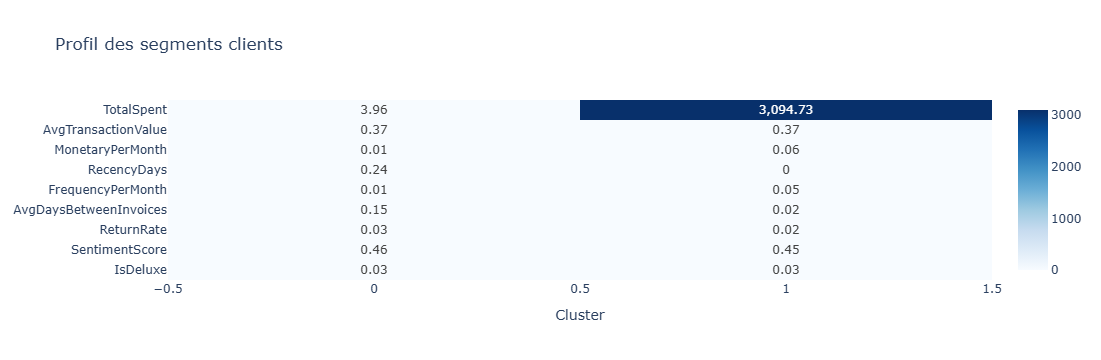

In [12]:
import plotly.express as px

fig = px.imshow(cluster_profile.T, text_auto=True, 
                color_continuous_scale='Blues',
                title="Profil des segments clients")
fig.show()
